# 05 — Validação da harmonização (A7, R6) e variante dia/noite (A8)

**Pergunta:** o fator `k` (VIIRS S-NPP ÷ MODIS por satélite × bloco 5° × mês do ano, calibrado em 2012–2021) prevê bem um ano que **não** entrou na calibração?

**Como:** *leave-one-year-out* (LOYO) em 2012–2021 — para cada ano Y, o `k` é recalculado com os outros 9 anos (mesmo método e mesmo *fallback* nacional do notebook 04), aplicado ao MODIS de Y e comparado com o VIIRS S-NPP real de Y. Também medimos 2022–2025 (fora da calibração, `k` de 2012–2021 inteiro), onde entra a deriva orbital de Terra/Aqua.

**Escalas:** série mensal nacional · bloco 5° × mês · célula 0,25° × mês.

**Métricas:**
- correlação de Pearson dos valores mensais (na célula também em `log1p`);
- erro relativo anual `previsto/real − 1` (média do valor absoluto);
- acerto do mês de pico: fração de unidades (anos no nacional; blocos e células com ≥ 50 focos VIIRS no ano) cujo mês de máximo previsto = mês de máximo real.

**Critério de aceite A2 (spec):** correlação mensal ≥ 0,85 **e** mês de pico correto em ≥ 80% das células com fogo.

> Foco detectado ≠ incêndio ≠ área queimada. Aqui só comparamos contagens de focos entre sensores.

In [1]:
import json, datetime as dt
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

PROC, REP = Path('../data/processed'), Path('../reports')
CAL = list(range(2012, 2022))          # anos de calibração
FORA = list(range(2022, 2026))         # fora da calibração
MIN_FOCOS = 30                         # abaixo disso o bloco×mês usa o k nacional (igual ao notebook 04)
MIN_PICO = 50                          # unidades com >= 50 focos VIIRS no ano entram no mês de pico / erro anual
OKABE = {'real': '#0072B2', 'prev': '#E69F00', 'loyo': '#009E73', 'fora': '#D55E00', 'cinza': '#999999'}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

grid = pd.read_parquet(PROC / 'grid_sat.parquet')
grid = grid[grid.ano >= 2012].groupby(['lat', 'lon', 'bloco_lat', 'bloco_lon', 'ano', 'mes', 'satellite', 'daynight'],
                                       as_index=False).n.sum()
# o bloco é o canto SW do quadrado de 5°: confere com a coluna gravada
assert (np.floor(grid.lat / 5) * 5 == grid.bloco_lat).all() and (np.floor(grid.lon / 5) * 5 == grid.bloco_lon).all()
print(f'{len(grid):,} linhas (2012–2025)'); grid.groupby('satellite').n.sum()

2,002,069 linhas (2012–2025)


satellite
Aqua      2805789
S-NPP    17124344
Terra     1778109
Name: n, dtype: int64

## 1. Funções: fator `k`, previsão e métricas

`fatores(cal, dia_noite)` reproduz o notebook 04: soma por bloco × mês (× dia/noite na variante A8) nos anos de calibração; se o satélite tem < 30 focos naquele grupo, usa o `k` nacional do mês. Blocos que não aparecem na calibração também caem no nacional.

In [2]:
BLOCO = ['bloco_lat', 'bloco_lon']

def fatores(cal, dia_noite=False):
    g = ['mes'] + (['daynight'] if dia_noite else [])
    out = []
    for sat in ['Terra', 'Aqua']:
        v = cal[cal.satellite == 'S-NPP'].groupby(BLOCO + g).n.sum().rename('n_viirs')
        m = cal[cal.satellite == sat].groupby(BLOCO + g).n.sum().rename('n_modis')
        d = pd.concat([v, m], axis=1).fillna(0).reset_index()
        nac = (cal[cal.satellite == 'S-NPP'].groupby(g).n.sum() / cal[cal.satellite == sat].groupby(g).n.sum()).rename('k_nac')
        d = d.merge(nac.reset_index(), on=g, how='left')
        d['k'] = np.where(d.n_modis < MIN_FOCOS, d.k_nac, d.n_viirs / d.n_modis.where(d.n_modis > 0))
        out.append(d.assign(satellite=sat))
    K = pd.concat(out, ignore_index=True)
    nac = K.groupby(['satellite'] + g).k_nac.first().reset_index()
    return K[BLOCO + g + ['satellite', 'k']], nac

def prever(alvo, K, nac, dia_noite=False):
    # alvo: linhas de grid dos anos a prever. Devolve célula × mês com prev (MODIS convertido) e real (VIIRS S-NPP).
    g = ['mes'] + (['daynight'] if dia_noite else [])
    m = alvo[alvo.satellite.isin(['Terra', 'Aqua'])]
    m = m.groupby(['lat', 'lon'] + BLOCO + ['ano', 'satellite'] + g, as_index=False).n.sum()
    m = m.merge(K, on=BLOCO + g + ['satellite'], how='left').merge(nac, on=['satellite'] + g, how='left')
    m['k'] = m.k.fillna(m.k_nac)
    assert m.k.notna().all()
    m['est'] = m.n * m.k
    est = m.pivot_table(index=['lat', 'lon', 'ano', 'mes'], columns='satellite', values='est', aggfunc='sum', fill_value=0)
    prev = ((est.get('Terra', 0) + est.get('Aqua', 0)) / 2).rename('prev')   # >= 2012: Terra e Aqua sempre ativos
    real = alvo[alvo.satellite == 'S-NPP'].groupby(['lat', 'lon', 'ano', 'mes']).n.sum().rename('real')
    d = pd.concat([prev, real], axis=1).fillna(0).reset_index()
    d['bloco_lat'], d['bloco_lon'] = np.floor(d.lat / 5) * 5, np.floor(d.lon / 5) * 5
    return d

def loyo(dia_noite=False):
    partes = []
    for y in CAL:
        K, nac = fatores(grid[grid.ano.isin([a for a in CAL if a != y])], dia_noite)
        partes.append(prever(grid[grid.ano == y], K, nac, dia_noite))
    return pd.concat(partes, ignore_index=True)

def fora_calibracao(dia_noite=False):
    K, nac = fatores(grid[grid.ano.isin(CAL)], dia_noite)
    return prever(grid[grid.ano.isin(FORA)], K, nac, dia_noite), prever(grid[grid.ano.isin(CAL)], K, nac, dia_noite)

In [3]:
def pico(d, chaves, min_real):
    # fração de unidades-ano (com >= min_real focos VIIRS no ano) cujo mês de máximo previsto == real; também com tolerância de ±1 mês
    t = d.groupby(chaves + ['ano', 'mes'])[['prev', 'real']].sum()
    tot = t.groupby(level=chaves + ['ano']).real.sum()
    ok = tot[tot >= min_real].index
    t = t.reset_index().set_index(chaves + ['ano']).loc[ok].reset_index()
    mp = t.pivot_table(index=chaves + ['ano'], columns='mes', values='prev', fill_value=0).reindex(columns=range(1, 13), fill_value=0)
    mr = t.pivot_table(index=chaves + ['ano'], columns='mes', values='real', fill_value=0).reindex(columns=range(1, 13), fill_value=0)
    a, b = mp.values.argmax(1), mr.values.argmax(1)
    dif = np.abs(a - b); dif = np.minimum(dif, 12 - dif)
    return {'acerto_mes_pico': float((dif == 0).mean()), 'acerto_mes_pico_mais_menos_1': float((dif <= 1).mean()), 'n_unidades_ano': int(len(a))}

def erro_anual(d, chaves, min_real):
    t = d.groupby(chaves + ['ano'])[['prev', 'real']].sum()
    t = t[t.real >= min_real]
    e = t.prev / t.real - 1
    return {'erro_rel_anual_medio_abs': float(e.abs().mean()), 'erro_rel_anual_mediana_abs': float(e.abs().median()),
            'vies_total': float(t.prev.sum() / t.real.sum() - 1)}

def metricas(d):
    nac = d.groupby(['ano', 'mes'])[['prev', 'real']].sum()
    ea = nac.groupby(level='ano').sum().pipe(lambda x: x.prev / x.real - 1)
    pn = pico(d.assign(pais='BR'), ['pais'], 0)
    r = {'nacional': {'correlacao_mensal': float(nac.prev.corr(nac.real)),
                      'erro_rel_anual_medio_abs': float(ea.abs().mean()),
                      'erro_rel_anual_por_ano': {int(k): float(v) for k, v in ea.items()},
                      'acerto_mes_pico': pn['acerto_mes_pico'], 'acerto_mes_pico_mais_menos_1': pn['acerto_mes_pico_mais_menos_1'],
                      'n_anos': pn['n_unidades_ano']}}
    bl = d.groupby(BLOCO + ['ano', 'mes'])[['prev', 'real']].sum()
    r['bloco'] = {'correlacao_mensal': float(bl.prev.corr(bl.real)),
                  'correlacao_mensal_log1p': float(np.log1p(bl.prev).corr(np.log1p(bl.real))),
                  'n_bloco_mes': int(len(bl)), **erro_anual(d, BLOCO, MIN_PICO), **pico(d, BLOCO, MIN_PICO)}
    r['celula'] = {'correlacao_mensal': float(d.prev.corr(d.real)),
                   'correlacao_mensal_log1p': float(np.log1p(d.prev).corr(np.log1p(d.real))),
                   'n_celula_mes': int(len(d)), **erro_anual(d, ['lat', 'lon'], MIN_PICO), **pico(d, ['lat', 'lon'], MIN_PICO)}
    return r

def tabela(r):
    linhas = []
    for esc in ['nacional', 'bloco', 'celula']:
        x = r[esc]
        linhas.append({'escala': esc, 'corr': x['correlacao_mensal'], 'corr_log1p': x.get('correlacao_mensal_log1p', np.nan),
                       'erro_anual_abs': x['erro_rel_anual_medio_abs'], 'pico': x['acerto_mes_pico'],
                       'pico_±1': x['acerto_mes_pico_mais_menos_1']})
    return pd.DataFrame(linhas).set_index('escala').round(3)

## 2. Leave-one-year-out 2012–2021 (método base)

Cada linha da tabela abaixo é uma **previsão fora da amostra**: o ano previsto nunca entrou no cálculo do seu `k`. Célula × mês inclui toda combinação em que MODIS **ou** VIIRS tem foco (pares 0 × 0 ficam de fora, o que é conservador para a correlação).

In [4]:
d_loyo = loyo()
d_fora, d_in = fora_calibracao()
M = {'loyo': metricas(d_loyo), 'fora': metricas(d_fora), 'in': metricas(d_in)}
for nome, chave in [('LOYO 2012–2021', 'loyo'), ('Dentro da amostra 2012–2021 (referência)', 'in'), ('Fora da calibração 2022–2025', 'fora')]:
    print(nome); display(tabela(M[chave]))

LOYO 2012–2021


,corr,corr_log1p,erro_anual_abs,pico,pico_±1
escala,,,,,
nacional,0.998,NaN,0.020,0.900,1.000
bloco,0.996,0.974,0.102,0.804,0.957
celula,0.951,0.757,0.290,0.727,0.898


Dentro da amostra 2012–2021 (referência)


,corr,corr_log1p,erro_anual_abs,pico,pico_±1
escala,,,,,
nacional,0.999,NaN,0.017,0.900,1.000
bloco,0.997,0.976,0.093,0.822,0.962
celula,0.953,0.758,0.287,0.729,0.899


Fora da calibração 2022–2025


,corr,corr_log1p,erro_anual_abs,pico,pico_±1
escala,,,,,
nacional,0.991,NaN,0.071,0.750,1.000
bloco,0.986,0.972,0.161,0.819,0.938
celula,0.948,0.745,0.345,0.709,0.893


In [5]:
print('Viés total (prev/real − 1) e mediana do erro anual absoluto, LOYO:')
pd.DataFrame({e: {k: M['loyo'][e][k] for k in ['vies_total', 'erro_rel_anual_mediana_abs', 'n_unidades_ano']} for e in ['bloco', 'celula']}).round(3)

Viés total (prev/real − 1) e mediana do erro anual absoluto, LOYO:


,bloco,celula
vies_total,0.004,0.001
erro_rel_anual_mediana_abs,0.058,0.223
n_unidades_ano,443.000,49106.000


**Sensibilidade do mês de pico ao limiar de fogo na célula.** Uma célula com 50 focos VIIRS no ano tem só ~5–8 focos MODIS; com tão poucos, o mês de máximo do MODIS é em boa parte sorte. A tabela mostra como o acerto muda quando exigimos mais fogo (informativo; o limiar oficial continua 50).

In [6]:
sens = pd.DataFrame({lim: pico(d_loyo, ['lat', 'lon'], lim) for lim in [10, 50, 100, 200, 500, 1000]}).T
sens.index.name = 'min_focos_viirs_ano'
M['sens_pico_celula'] = {int(k): {**v, 'n_unidades_ano': int(v['n_unidades_ano'])} for k, v in sens.to_dict('index').items()}
sens.round(3)

,acerto_mes_pico,acerto_mes_pico_mais_menos_1,n_unidades_ano
min_focos_viirs_ano,,,
10,0.631,0.822,79578.0
50,0.727,0.898,49106.0
100,0.779,0.929,32123.0
200,0.830,0.954,17285.0
500,0.887,0.979,4794.0
1000,0.920,0.991,1069.0


## 3. Figuras

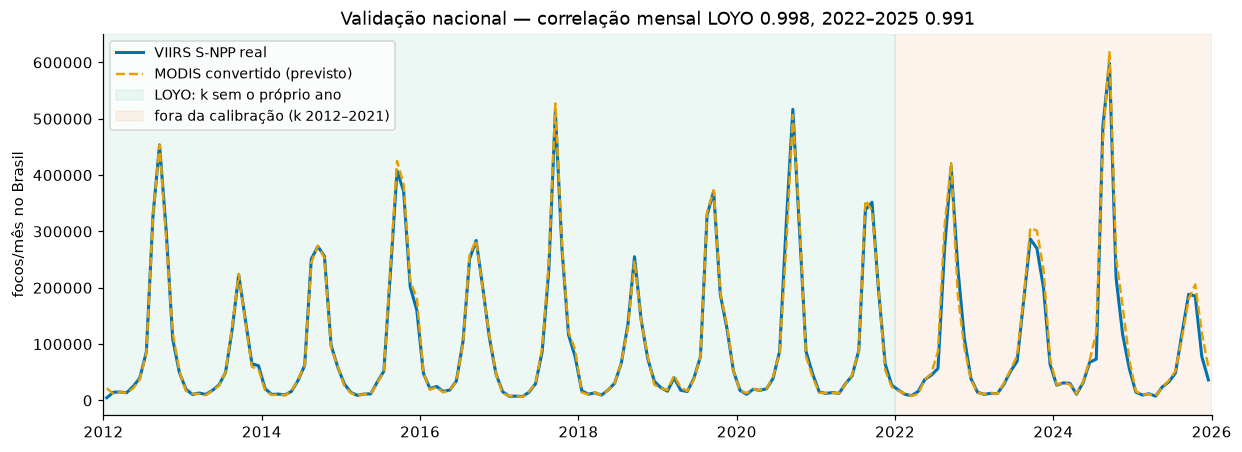

In [7]:
nac = pd.concat([d_loyo, d_fora]).groupby(['ano', 'mes'])[['prev', 'real']].sum().reset_index()
x = nac.ano + (nac.mes - .5) / 12
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(x, nac.real, c=OKABE['real'], lw=2, label='VIIRS S-NPP real')
ax.plot(x, nac.prev, c=OKABE['prev'], lw=1.6, ls='--', label='MODIS convertido (previsto)')
ax.axvspan(2012, 2022, color=OKABE['loyo'], alpha=.07, label='LOYO: k sem o próprio ano')
ax.axvspan(2022, 2026, color=OKABE['fora'], alpha=.07, label='fora da calibração (k 2012–2021)')
ax.set_ylabel('focos/mês no Brasil'); ax.set_xlim(2012, 2026); ax.legend(loc='upper left', fontsize=9)
ax.set_title(f"Validação nacional — correlação mensal LOYO {M['loyo']['nacional']['correlacao_mensal']:.3f}, "
             f"2022–2025 {M['fora']['nacional']['correlacao_mensal']:.3f}")
fig.savefig(REP / 'validacao_loyo_mensal.png', bbox_inches='tight'); plt.show()

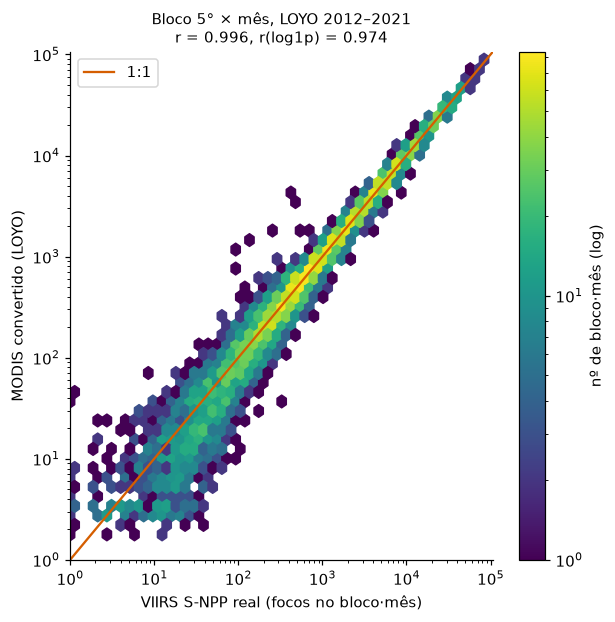

4,910 bloco·mês com foco nos dois sensores (os demais não aparecem em escala log)


In [8]:
bl = d_loyo.groupby(BLOCO + ['ano', 'mes'])[['prev', 'real']].sum()
bl = bl[(bl.prev > 0) & (bl.real > 0)]
fig, ax = plt.subplots(figsize=(6.2, 6))
hb = ax.hexbin(bl.real, bl.prev, xscale='log', yscale='log', gridsize=45, bins='log', cmap='viridis', mincnt=1)
lim = [1, max(bl.real.max(), bl.prev.max()) * 1.2]
ax.plot(lim, lim, c=OKABE['fora'], lw=1.5, label='1:1')
ax.set_xlim(lim); ax.set_ylim(lim); ax.set_xlabel('VIIRS S-NPP real (focos no bloco·mês)'); ax.set_ylabel('MODIS convertido (LOYO)')
ax.set_title(f"Bloco 5° × mês, LOYO 2012–2021\nr = {M['loyo']['bloco']['correlacao_mensal']:.3f}, "
             f"r(log1p) = {M['loyo']['bloco']['correlacao_mensal_log1p']:.3f}", fontsize=10)
fig.colorbar(hb, ax=ax, label='nº de bloco·mês (log)'); ax.legend(loc='upper left')
fig.savefig(REP / 'validacao_dispersao_blocos.png', bbox_inches='tight'); plt.show()
print(f'{len(bl):,} bloco·mês com foco nos dois sensores (os demais não aparecem em escala log)')

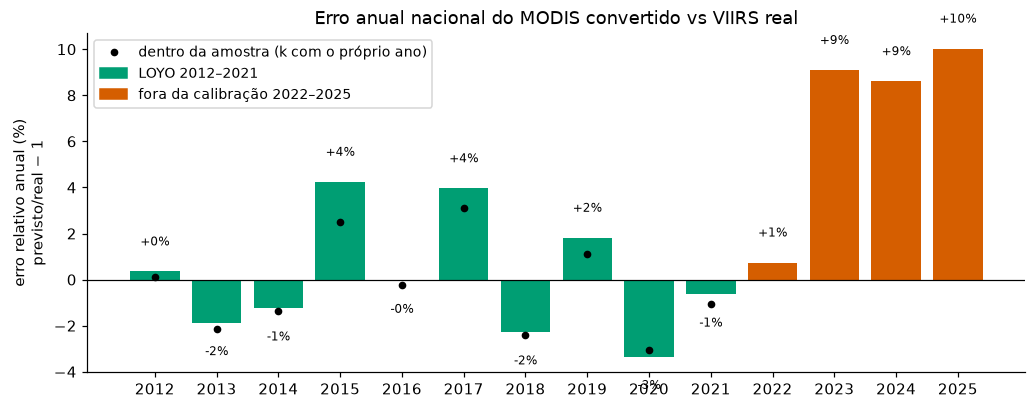

In [9]:
ea = pd.Series({**M['loyo']['nacional']['erro_rel_anual_por_ano'], **M['fora']['nacional']['erro_rel_anual_por_ano']})
ea_in = pd.Series(M['in']['nacional']['erro_rel_anual_por_ano'])
fig, ax = plt.subplots(figsize=(11, 4))
cores = [OKABE['loyo'] if a <= 2021 else OKABE['fora'] for a in ea.index]
ax.bar(ea.index, 100 * ea.values, color=cores)
ax.plot(ea_in.index, 100 * ea_in.values, 'o', c='k', ms=4, label='dentro da amostra (k com o próprio ano)')
for a, v in ea.items(): ax.text(a, 100 * v + (1 if v >= 0 else -1), f'{100*v:+.0f}%', ha='center', va='bottom' if v >= 0 else 'top', fontsize=8)
ax.axhline(0, c='k', lw=.8)
from matplotlib.patches import Patch
h0, _ = ax.get_legend_handles_labels()
ax.set_ylabel('erro relativo anual (%)\nprevisto/real − 1'); ax.set_xticks(ea.index)
ax.legend(handles=h0 + [Patch(color=OKABE['loyo'], label='LOYO 2012–2021'), Patch(color=OKABE['fora'], label='fora da calibração 2022–2025')],
          fontsize=9, loc='upper left')
ax.set_title('Erro anual nacional do MODIS convertido vs VIIRS real')
fig.savefig(REP / 'validacao_erro_anual.png', bbox_inches='tight'); plt.show()

## 4. A8 (opcional) — `k` separado para dia e noite

Mesma regra, mas o grupo vira satélite × dia/noite × bloco × mês (fallback: `k` nacional do satélite × dia/noite × mês). O VIIRS detecta proporcionalmente mais focos à noite, então em tese ajuda; na prática divide os dados e aumenta o uso de fallback.

In [10]:
d_loyo_dn = loyo(dia_noite=True)
M['loyo_dn'] = metricas(d_loyo_dn)
comp = pd.concat({'base': tabela(M['loyo']), 'dia/noite': tabela(M['loyo_dn'])}, axis=1).swaplevel(axis=1).sort_index(axis=1, level=0)
display(comp)
cmp_cel = {k: (M['loyo_dn']['celula'][k], M['loyo']['celula'][k]) for k in ['correlacao_mensal', 'correlacao_mensal_log1p', 'acerto_mes_pico']}
melhor = (all(a >= b for a, b in cmp_cel.values()) and
          M['loyo_dn']['nacional']['erro_rel_anual_medio_abs'] <= M['loyo']['nacional']['erro_rel_anual_medio_abs'])
dif = {e: {k: round(M['loyo_dn'][e][k] - M['loyo'][e][k], 3) for k in ['correlacao_mensal', 'erro_rel_anual_medio_abs', 'acerto_mes_pico']}
       for e in ['nacional', 'bloco', 'celula']}
print('Diferença (dia/noite − base):', dif)
print('Recomendação:', 'ADOTAR k dia/noite (melhora todas as métricas de célula e o erro nacional)' if melhor
      else 'MANTER o método base (a variante não melhora todas as métricas de forma consistente)')

corr           corr_log1p           erro_anual_abs            \
           base dia/noite       base dia/noite           base dia/noite   
escala                                                                    
nacional  0.998     0.998        NaN       NaN          0.020     0.028   
bloco     0.996     0.995      0.974     0.975          0.102     0.117   
celula    0.951     0.940      0.757     0.760          0.290     0.324   

           pico           pico_±1            
           base dia/noite    base dia/noite  
escala                                       
nacional  0.900     0.900   1.000     1.000  
bloco     0.804     0.792   0.957     0.950  
celula    0.727     0.714   0.898     0.891

Diferença (dia/noite − base): {'nacional': {'correlacao_mensal': -0.001, 'erro_rel_anual_medio_abs': 0.008, 'acerto_mes_pico': 0.0}, 'bloco': {'correlacao_mensal': -0.001, 'erro_rel_anual_medio_abs': 0.015, 'acerto_mes_pico': -0.011}, 'celula': {'correlacao_mensal': -0.011, 'erro_rel_anual_medio_abs': 0.033, 'acerto_mes_pico': -0.013}}
Recomendação: MANTER o método base (a variante não melhora todas as métricas de forma consistente)


## 5. Aceite A2 e `reports/metrics.json`

A spec pede correlação mensal ≥ 0,85 e mês de pico correto em ≥ 80% das **células com fogo**. A escala oficial do aceite é, portanto, a **célula 0,25°** em LOYO (células com ≥ 50 focos VIIRS no ano). Mostramos as outras escalas para ser transparente sobre onde o método é forte e onde é fraco.

In [11]:
CRIT_CORR, CRIT_PICO = 0.85, 0.80
linhas = []
for esc in ['nacional', 'bloco', 'celula']:
    x = M['loyo'][esc]
    linhas.append({'escala': esc, 'correlacao': x['correlacao_mensal'], 'passa_corr': x['correlacao_mensal'] >= CRIT_CORR,
                   'mes_pico': x['acerto_mes_pico'], 'passa_pico': x['acerto_mes_pico'] >= CRIT_PICO})
A2 = pd.DataFrame(linhas).set_index('escala')
cel = M['loyo']['celula']
passa = bool(A2.loc['celula', 'passa_corr'] and A2.loc['celula', 'passa_pico'])
escalas_ok = [e for e in A2.index if A2.loc[e, 'passa_corr'] and A2.loc[e, 'passa_pico']]
detalhe = (f"Escala oficial (célula 0,25°, LOYO 2012–2021): correlação mensal {cel['correlacao_mensal']:.3f} "
           f"({'≥' if cel['correlacao_mensal'] >= CRIT_CORR else '<'} 0,85; log1p {cel['correlacao_mensal_log1p']:.3f}) e mês de pico "
           f"{cel['acerto_mes_pico']:.1%} ({'≥' if cel['acerto_mes_pico'] >= CRIT_PICO else '<'} 80%; ±1 mês {cel['acerto_mes_pico_mais_menos_1']:.1%}) "
           f"em {cel['n_unidades_ano']:,} célula·ano com ≥ {MIN_PICO} focos VIIRS. "
           f"Escalas que passam nos dois critérios: {', '.join(escalas_ok) if escalas_ok else 'nenhuma'}.")
print('=' * 80); print('ACEITE A2:', 'PASSA' if passa else 'NÃO PASSA'); print(detalhe); print('=' * 80)
A2.round(3)

ACEITE A2: NÃO PASSA
Escala oficial (célula 0,25°, LOYO 2012–2021): correlação mensal 0.951 (≥ 0,85; log1p 0.757) e mês de pico 72.7% (< 80%; ±1 mês 89.8%) em 49,106 célula·ano com ≥ 50 focos VIIRS. Escalas que passam nos dois critérios: nacional, bloco.


,correlacao,passa_corr,mes_pico,passa_pico
escala,,,,
nacional,0.998,True,0.900,True
bloco,0.996,True,0.804,True
celula,0.951,True,0.727,False


In [12]:
def arred(o):
    if isinstance(o, dict): return {str(k): arred(v) for k, v in o.items()}
    if isinstance(o, (float, np.floating)): return round(float(o), 3)
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    return o

metrics = {
    'descricao': {
        'metodo': 'k_sat = soma(VIIRS S-NPP)/soma(MODIS sat) por satelite (Terra, Aqua) x bloco 5 graus x mes do ano; '
                  'fallback k nacional do mes se soma MODIS < 30; modis_convertido = (Terra*k_Terra + Aqua*k_Aqua)/2',
        'loyo': 'para cada ano Y em 2012-2021, k calculado com os outros 9 anos e aplicado a Y',
        'correlacao_mensal': 'Pearson entre previsto e real por unidade x mes (celula: pares com foco em ao menos um sensor)',
        'erro_rel_anual_medio_abs': 'media de |previsto/real - 1| por unidade x ano (bloco/celula: so unidades com >= 50 focos VIIRS no ano)',
        'acerto_mes_pico': 'fracao de unidade x ano em que o mes de maximo previsto = real (bloco/celula: >= 50 focos VIIRS no ano)',
        'vies_total': 'soma(previsto)/soma(real) - 1 no subconjunto avaliado',
    },
    'loyo_2012_2021': M['loyo'],
    'dentro_amostra_2012_2021': M['in'],
    'fora_calibracao_2022_2025': M['fora'],
    'aceite_A2': {'passa': passa, 'escala_oficial': 'celula', 'criterio': 'correlacao mensal >= 0.85 e acerto mes de pico >= 0.80',
                  'escalas_que_passam': escalas_ok, 'detalhe': detalhe},
    'sensibilidade_pico_celula_loyo': M['sens_pico_celula'],
    'variante_dia_noite': {'loyo_2012_2021': M['loyo_dn'], 'diferenca_vs_base': dif, 'melhora': bool(melhor),
                           'recomendacao': 'adotar' if melhor else 'manter metodo base'},
    'gerado_em': dt.datetime.now().isoformat(timespec='seconds'),
}
(REP / 'metrics.json').write_text(json.dumps(arred(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print('reports/metrics.json gravado,', (REP / 'metrics.json').stat().st_size, 'bytes')

reports/metrics.json gravado, 7574 bytes


## Conclusão

A tabela abaixo é gerada a partir das métricas calculadas acima (LOYO 2012–2021, método base, salvo indicação).

In [13]:
L, F = M['loyo'], M['fora']
linhas = [
    ('correlação mensal', 'nacional', L['nacional']['correlacao_mensal'], '≥ 0,85'),
    ('correlação mensal', 'bloco 5°', L['bloco']['correlacao_mensal'], '≥ 0,85'),
    ('correlação mensal', 'célula 0,25°', L['celula']['correlacao_mensal'], '≥ 0,85 (A2)'),
    ('correlação mensal log1p', 'célula 0,25°', L['celula']['correlacao_mensal_log1p'], '≥ 0,85'),
    ('mês de pico', 'nacional (anos)', L['nacional']['acerto_mes_pico'], '≥ 80%'),
    ('mês de pico', 'bloco 5°', L['bloco']['acerto_mes_pico'], '≥ 80%'),
    ('mês de pico', 'célula 0,25°', L['celula']['acerto_mes_pico'], '≥ 80% (A2)'),
    ('mês de pico ±1 mês', 'célula 0,25°', L['celula']['acerto_mes_pico_mais_menos_1'], '(informativo)'),
    ('erro relativo anual (abs)', 'nacional', L['nacional']['erro_rel_anual_medio_abs'], '(informativo)'),
    ('erro relativo anual (abs)', 'bloco 5°', L['bloco']['erro_rel_anual_medio_abs'], '(informativo)'),
    ('erro relativo anual (abs)', 'célula 0,25°', L['celula']['erro_rel_anual_medio_abs'], '(informativo)'),
    ('correlação mensal 2022–2025', 'nacional', F['nacional']['correlacao_mensal'], '≥ 0,85'),
    ('correlação mensal 2022–2025', 'célula 0,25°', F['celula']['correlacao_mensal'], '≥ 0,85'),
    ('mês de pico 2022–2025', 'célula 0,25°', F['celula']['acerto_mes_pico'], '≥ 80%'),
    ('erro relativo anual 2022–2025', 'nacional', F['nacional']['erro_rel_anual_medio_abs'], '(informativo)'),
]
def passa_txt(m, v, c):
    if 'informativo' in c: return '—'
    return 'sim' if v >= (0.85 if 'correla' in m else 0.80) else 'não'
from IPython.display import Markdown
md_tab = '| métrica | escala | valor | critério | passa? |\n|---|---|---|---|---|\n' + '\n'.join(
    f"| {m} | {e} | {v:.3f} | {c} | {passa_txt(m, v, c)} |" for m, e, v, c in linhas)
display(Markdown(md_tab + f"\n\n**Aceite A2 (célula, LOYO): {'PASSA' if passa else 'NÃO PASSA'}.** {detalhe}\n\n"
                 f"**Variante dia/noite (A8):** {'melhora — adotar' if melhor else 'não melhora de forma consistente — manter o método base'}."))

| métrica | escala | valor | critério | passa? |
|---|---|---|---|---|
| correlação mensal | nacional | 0.998 | ≥ 0,85 | sim |
| correlação mensal | bloco 5° | 0.996 | ≥ 0,85 | sim |
| correlação mensal | célula 0,25° | 0.951 | ≥ 0,85 (A2) | sim |
| correlação mensal log1p | célula 0,25° | 0.757 | ≥ 0,85 | não |
| mês de pico | nacional (anos) | 0.900 | ≥ 80% | sim |
| mês de pico | bloco 5° | 0.804 | ≥ 80% | sim |
| mês de pico | célula 0,25° | 0.727 | ≥ 80% (A2) | não |
| mês de pico ±1 mês | célula 0,25° | 0.898 | (informativo) | — |
| erro relativo anual (abs) | nacional | 0.020 | (informativo) | — |
| erro relativo anual (abs) | bloco 5° | 0.102 | (informativo) | — |
| erro relativo anual (abs) | célula 0,25° | 0.290 | (informativo) | — |
| correlação mensal 2022–2025 | nacional | 0.991 | ≥ 0,85 | sim |
| correlação mensal 2022–2025 | célula 0,25° | 0.948 | ≥ 0,85 | sim |
| mês de pico 2022–2025 | célula 0,25° | 0.709 | ≥ 80% | não |
| erro relativo anual 2022–2025 | nacional | 0.071 | (informativo) | — |

**Aceite A2 (célula, LOYO): NÃO PASSA.** Escala oficial (célula 0,25°, LOYO 2012–2021): correlação mensal 0.951 (≥ 0,85; log1p 0.757) e mês de pico 72.7% (< 80%; ±1 mês 89.8%) em 49,106 célula·ano com ≥ 50 focos VIIRS. Escalas que passam nos dois critérios: nacional, bloco.

**Variante dia/noite (A8):** não melhora de forma consistente — manter o método base.

### Limitações

- **Dentro da amostra × LOYO:** a correlação nacional 0,999 do notebook 04 é *dentro da amostra* (o ano avaliado ajudou a calcular o `k`). O LOYO é a medida honesta; a diferença entre as duas mostra quanto o `k` "decora" cada ano — aqui ela é pequena, porque o `k` é uma razão de somas de 9–10 anos.
- **Deriva orbital:** depois de 2021 Terra e Aqua mudaram o horário de passagem; por isso 2022–2025 tem erro anual maior com o `k` de 2012–2021. A série harmonizada usa VIIRS real a partir de 2012, então isso afeta só a validação, não o produto.
- **Células com pouco fogo:** com poucos focos, o mês de pico é ruído de contagem (Poisson) e o erro relativo explode; por isso o mês de pico e o erro anual na célula usam só célula·ano com ≥ 50 focos VIIRS. A correlação célula × mês é puxada pelas células com muito fogo; a versão `log1p` dá peso às pequenas.
- **Previsão é de contagem média:** o `k` corrige o nível do sensor por região e época, não a geometria de cada foco (pixel 1 km × 375 m, duplicatas do VIIRS). Foco detectado ≠ incêndio ≠ área queimada.